# OPT 212: Asphere form error analysis and Zernike fitting

In this exercise you will analyze real measurement data from the front surface (R1) of the OptiPro Demo Asphere (see the technical drawing provided on Blackboard). The data you took is a point-cloud measurement (a 1 mm pitch symmetric spiral) saved in an `.opm` file. You will compare the measurement with the nominal surface from the drawing, quantify the form error, and then fit the error with Zernike polynomials just as in the Week 4 class activity.

**The data file** The data file has a short header followed by 7 comma-separated columns (all lengths in mm):

| Column | Meaning |
|---|---|
| `X0, Y0, Z0` | measured point cloud (the sag of the surface) |
| `Error0` | form error along the surface normal reported by the instrument |
| `NX0, NY0, NZ0` | components of the nominal surface normal at each point |

**The nominal surface** (from the drawing, R1, "Asphere Box") is a conic plus an 8th-order term:

$$z(r) = \frac{c\,r^2}{1+\sqrt{1-(1+K)\,c^2 r^2}} + A_8\, r^8, \qquad c = \frac{1}{R}, \quad r^2 = x^2 + y^2$$

where $R$ is the radius of curvature, $K$ is the conic constant and $A_8$ is the 8th aspheric coefficient (all other aspheric coefficients are zero).

**Steps**
1. Import the data and plot the measured sag.
2. Calculate the nominal sag at the same $(x, y)$ points.
3. Calculate the measured form error and plot it.
4. Look for edge artifacts (roll-off) and mask the data to a smaller aperture.
5. Fit the masked form error to Zernike polynomials.
6. Remove piston, tip, and tilt from the fit.
7. Evaluate the fitted residual (no piston, tip, tilt) on a new uniform XY grid and plot it.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

### Defines the Zernike Polynomials for our calculations

This is the same function you used in the Week 4 activity. It takes **1D arrays** `x` and `y` that are already normalized to the unit circle and returns a matrix with one row per point and 36 columns. Column 0 is piston, column 1 is x-tilt, column 2 is y-tilt, column 3 is power, and so on.

In [5]:
def Zernike(x, y):
    ro2 = x**2 + y**2
    ro = np.sqrt(ro2)
    ro3 = ro**3
    ro4 = ro**4
    ro5 = ro**5
    ro6 = ro**6
    ro7 = ro**7
    ro8 = ro**8
    ro10 = ro**10

    theta = np.arctan2(y, x)

    n = len(x)
    Zer = np.zeros((n, 35))

    Zer[:, 0] = ro * np.cos(theta)       # x tilt
    Zer[:, 1] = ro * np.sin(theta)
    Zer[:, 2] = -1 + 2 * ro2
    Zer[:, 3] = ro2 * np.cos(2 * theta)
    Zer[:, 4] = ro2 * np.sin(2 * theta)
    Zer[:, 5] = ro * (-2 + 3 * ro2) * np.cos(theta)
    Zer[:, 6] = ro * (-2 + 3 * ro2) * np.sin(theta)
    Zer[:, 7] = 1 - 6 * ro2 + 6 * ro4
    Zer[:, 8] = ro3 * np.cos(3 * theta)
    Zer[:, 9] = ro3 * np.sin(3 * theta)
    Zer[:, 10] = ro2 * (-3 + 4 * ro2) * np.cos(2 * theta)
    Zer[:, 11] = ro2 * (-3 + 4 * ro2) * np.sin(2 * theta)
    Zer[:, 12] = ro * (3 - 12 * ro2 + 10 * ro4) * np.cos(theta)
    Zer[:, 13] = ro * (3 - 12 * ro2 + 10 * ro4) * np.sin(theta)
    Zer[:, 14] = -1 + 12 * ro2 - 30 * ro4 + 20 * ro6
    Zer[:, 15] = ro4 * np.cos(4 * theta)
    Zer[:, 16] = ro4 * np.sin(4 * theta)
    Zer[:, 17] = ro3 * (-4 + 5 * ro2) * np.cos(3 * theta)
    Zer[:, 18] = (5 * ro5 - 4 * ro3) * np.sin(3 * theta)
    Zer[:, 19] = (15 * ro6 - 20 * ro4 + 6 * ro2) * np.cos(2 * theta)
    Zer[:, 20] = (15 * ro6 - 20 * ro4 + 6 * ro2) * np.sin(2 * theta)
    Zer[:, 21] = (35 * ro7 - 60 * ro5 + 30 * ro3 - 4 * ro) * np.cos(theta)
    Zer[:, 22] = (35 * ro7 - 60 * ro5 + 30 * ro3 - 4 * ro) * np.sin(theta)
    Zer[:, 23] = (70 * ro**8 - 140 * ro**6 + 90 * ro**4 - 20 * ro**2 + 1)
    Zer[:, 24] = ro5 * np.cos(5 * theta)
    Zer[:, 25] = ro5 * np.sin(5 * theta)
    Zer[:, 26] = (6 * ro6 - 5 * ro4) * np.cos(4 * theta)
    Zer[:, 27] = (6 * ro6 - 5 * ro4) * np.sin(4 * theta)
    Zer[:, 28] = (21 * ro7 - 30 * ro5 + 10 * ro3) * np.cos(3 * theta)
    Zer[:, 29] = (21 * ro7 - 30 * ro5 + 10 * ro3) * np.sin(3 * theta)
    Zer[:, 30] = (56 * ro8 - 105 * ro6 + 60 * ro4 - 10 * ro2) * np.cos(2 * theta)
    Zer[:, 31] = (56 * ro8 - 105 * ro6 + 60 * ro4 - 10 * ro2) * np.sin(2 * theta)
    Zer[:, 32] = ro * (5 - 60 * ro2 + 210 * ro4 - 280 * ro6 + 126 * ro8) * np.cos(theta)
    Zer[:, 33] = ro * (5 - 60 * ro2 + 210 * ro4 - 280 * ro6 + 126 * ro8) * np.sin(theta)
    Zer[:, 34] = -1 + 30 * ro2 - 210 * ro4 + 560 * ro6 - 630 * ro8 + 252 * ro10

    Zout = np.column_stack((np.ones(n), Zer))
    return Zout

## Step 1: Import the data and plot the measured sag

**IMPORTANT:** Do the following to make sure your data file can be seen by your Jupyter Notebook in Colab:

1. Begin by downloading your measurement file from Blackboard. It will be named as you named it when you took the measurement in the lab. Use your own file only.

2. Make sure to put the .opm data file in the same folder as this Jupyter Notebook.

3. Using the explorer in VS Code open the folder where this notebook and the data file are. If you don't see the explorer on your left hand side in VS Code you can show it with CTRL+SHIFT+E.

4. If you have not done so yet, make sure to connect to Google Colab like we did in class.

5. You should see your .opm data file in the explorer. Right click on it and then click on "Upload to Colab." You should see a message that the file has been uploaded.

See the Blackboard assignment instructions for some step-by-step screenshots.


In [6]:
# Load the measurement data from the .opm file.

# REPLACE 'Example Data.opm' with the name of the .opm file of your measurement.

# The file is plain text. The first 13 lines are header information (open the file in a text
# editor to see them), followed by 7 columns of numbers separated by commas.
# HINT: np.loadtxt('filename', delimiter=',', skiprows=13, unpack=True) skips the header lines
#       and, with unpack=True, returns one 1D array per column so you can assign all 7 at once:
#       x, y, z, err_file, nx, ny, nz = np.loadtxt(...)

x, y, z, err_file, nx, ny, nz = np.loadtxt('Asphere_stakayama.opm', delimiter=',', skiprows=13, unpack=True)

If you see an error that your .opm file is not found, make sure you have correctly spelled your file name in the cell above and that you have followed the instructions above to upload the data file to Colab.

In [7]:
# Check what you loaded: how many points are there, and what are the ranges of x, y and z?
# HINT: x.size (or len(x)) is the number of points. x.min() and x.max() give the extremes.
#       An f-string makes nice output, e.g.  print(f"x range: {x.min():.3f} to {x.max():.3f} mm")

print(f"Number of points: {x.size}")
print(f"x range: {x.min():.3f} to {x.max():.3f} mm")
print(f"y range: {y.min():.3f} to {y.max():.3f} mm")
print(f"z range: {z.min():.3f} to {z.max():.3f} mm")

Number of points: 11908
x range: -24.529 to 24.082 mm
y range: -24.325 to 24.441 mm
z range: -6.500 to -0.000 mm


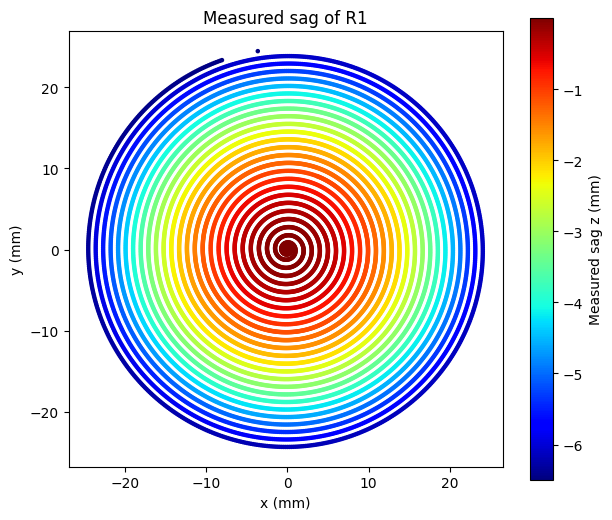

In [8]:
# Plot the measured sag. The points are not on a regular grid (they follow a spiral),
# so use a scatter plot with the color of each point showing its z value.

# I have added the full plotting code below so you can see it in action once.

# HINT: plt.scatter(x, y, c=z, s=5, cmap='jet') colors each point by z (s sets the marker size).
#       plt.colorbar(label='...') adds the color scale.
#       plt.gca().set_aspect('equal') makes one mm in x look the same as one mm in y.
#       Don't forget plt.xlabel(), plt.ylabel(), and plt.title(), and plt.show() at the end.

plt.figure(figsize=(7, 6))
plt.scatter(x, y, c=z, s=5, cmap='jet')
plt.colorbar(label='Measured sag z (mm)')
plt.gca().set_aspect('equal')
plt.xlabel('x (mm)')
plt.ylabel('y (mm)')
plt.title('Measured sag of R1')
plt.show()

## Step 2: Calculate the nominal sag

Look at your plot above: the measured $z$ values are **negative**, because in the measurement coordinate system the surface curves toward $-z$. To get the same sign from the sag equation, **make the radius from the technical drawing negative**.

In [9]:
# Write a function that returns the nominal sag z for any x and y (in mm) using the values from the drawing
# Use the value labeled as ROC but negative for the radius of curvature R
# Then use conic constant K = -1 and the aspheric coefficient A8
# HINT: Start with r2 = x**2 + y**2   (** is the power operator, and it works on whole arrays)
#       c = 1/R is the curvature. np.sqrt() takes the square root of an array.
#       In Python, 2.8x10^-12 is typed as 2.8e-12, and r^8 is r2**4.
#       Use `def nominal_sag(x, y):` ... `return z_nom` to define the function.

def nominal_sag(x, y):
    R = -45          # negative of the ROC from your drawing
    K = -1
    A8 = 2.80e-12          # A8 from your drawing

    r2 = x**2 + y**2
    c = 1 / R

    z_nom = (c * r2) / (1 + np.sqrt(1 - (1 + K) * c**2 * r2)) + A8 * r2**4

    return z_nom


# Evaluate the nominal sag at the measured x, y points
z_nom = nominal_sag(x, y)

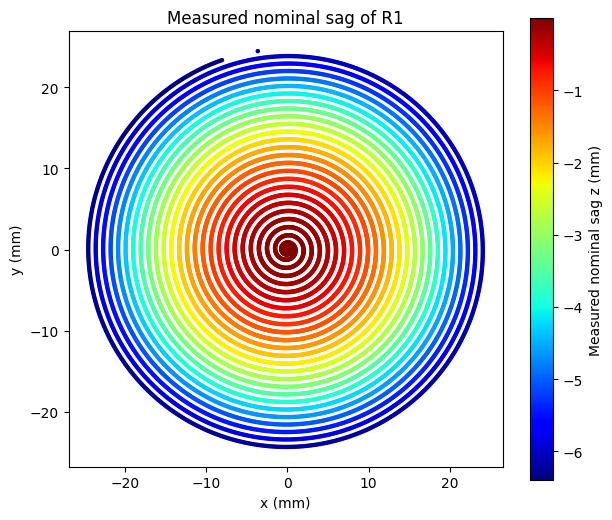

In [10]:
# Plot the nominal sag the same way you plotted the measured sag.
# It should look essentially identical -- the form error between the two is much smaller than the sag!

plt.figure(figsize=(7, 6))
plt.scatter(x, y, c=z_nom, s=5, cmap='jet')
plt.colorbar(label='Measured nominal sag z (mm)')
plt.gca().set_aspect('equal')
plt.xlabel('x (mm)')
plt.ylabel('y (mm)')
plt.title('Measured nominal sag of R1')
plt.show()

## Step 3: Calculate and plot the measured form error

In [11]:
# The error in z is the measured sag minus the nominal sag.
form_error = z - z_nom

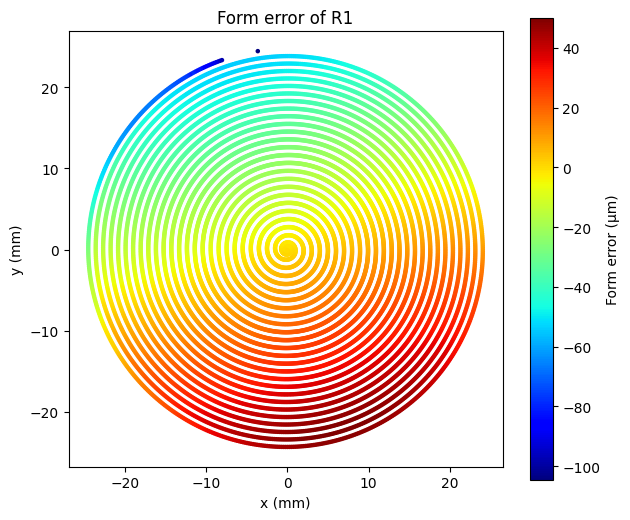

In [12]:
# Plot the form error. Convert from mm to microns to get easier numbers.
# Use a scatter plot again. Look carefully at the edge of the part.
# What do you notice about the color scale?

plt.figure(figsize=(7, 6))
plt.scatter(x, y, c=form_error*1000, s=5, cmap='jet')
plt.colorbar(label='Form error (µm)')
plt.gca().set_aspect('equal')
plt.xlabel('x (mm)')
plt.ylabel('y (mm)')
plt.title('Form error of R1')
plt.show()

# The colors seem to be having a gradient across the circular plot, not a
# gradient from the inside to outside of the circular plot like the previous two plots.

## Step 4: Mask the edge artifacts

The part has a bevel and the edge of the part rolls off, so the measurement near the edge does not describe the optical surface. To choose a smaller aperture, look at the form error as a function of radius.

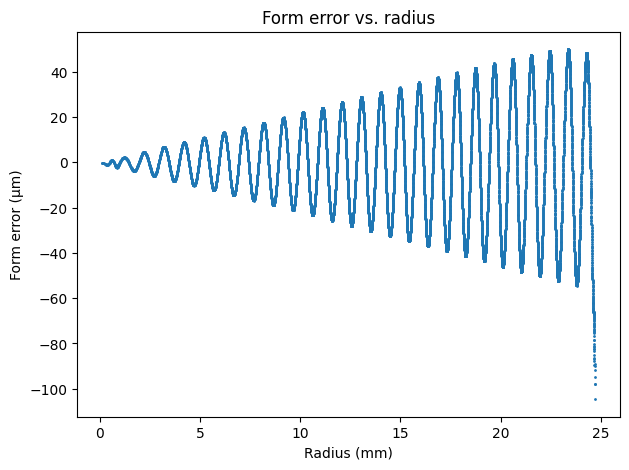

In [13]:
# Calculate the radius of every point and plot the form error versus radius.
# HINT: r = np.sqrt(x**2 + y**2)
#       plt.plot(r, form_error*1000, '.', markersize=2) plots dots without connecting lines.
#       Where does the error falls off?

r = np.sqrt(x**2 + y**2)

plt.figure(figsize=(7, 5))
plt.plot(r, form_error*1000, '.', markersize=2)
plt.xlabel('Radius (mm)')
plt.ylabel('Form error (µm)')
plt.title('Form error vs. radius')
plt.show()

#The error seems to fall off at around 24-24.5

In [14]:
# Choose a mask radius slightly inside where the roll-off starts, and keep only those points.
# (The part is 49.53 mm in diameter with a 0.5 mm bevel.)
# HINT: A comparison like (r <= 24.0) creates a True/False array (a "mask").
#       Use the mask to select points:  x_m = x[mask]   (do the same for y and form_error)
#       Replot the form error vs. radius using only the masked points. to see if the roll-off is gone.

r_mask = 24.0                 # mm

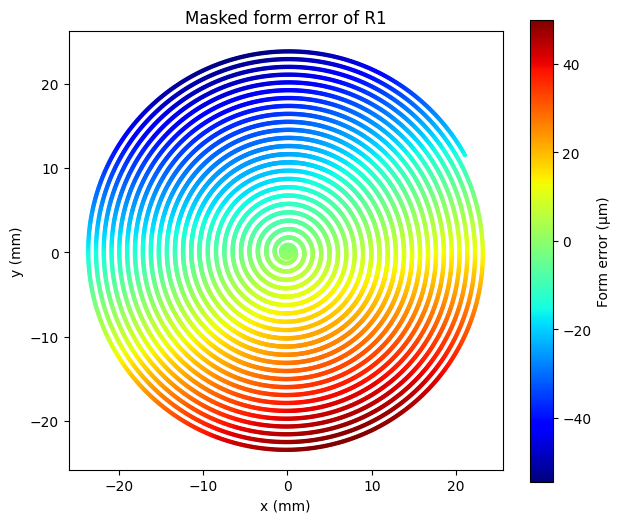

In [15]:
# Plot the masked form error. Now the color scale should show the structure of the real surface error.
# HINT: Same scatter plot as before, but with the masked x_m, y_m and err_m.

mask = r <= r_mask
x_m = x[mask]
y_m = y[mask]
err_m = form_error[mask]
r_m = r[mask]

plt.figure(figsize=(7, 6))
plt.scatter(x_m, y_m, c=err_m*1000, s=5, cmap='jet')
plt.colorbar(label='Form error (µm)')
plt.gca().set_aspect('equal')
plt.xlabel('x (mm)')
plt.ylabel('y (mm)')
plt.title('Masked form error of R1')
plt.show()

What is the dominant error you see?
I see a dominant y-tilt error, since the colors change from top to bottom of the circular plot in a linear fashion.

## Step 5: Fit the form error to Zernike polynomials

The Zernike polynomials are defined on the unit circle, so first normalize the coordinates by the mask radius. Then build the Zernike matrix at the measured points and solve for the coefficients, exactly as in the Week 4 activity.

In [16]:
# Normalize the coordinates so the edge of the masked aperture is at a radius of 1.
# HINT: Divide x_m and y_m by r_mask. Check your result: np.max(xn**2 + yn**2) should be <= 1.

xn = x_m / r_mask
yn = y_m / r_mask
np.max(xn**2 + yn**2)

np.float64(0.9999273828382523)

In [17]:
# Define the Zernike matrix at the measured points (one row per point, one column per term).
# HINT: Use the Zernike function defined above. It needs 1D arrays for x and y.
#       ZMatrix.shape tells you the number of rows and columns.

ZMatrix = Zernike(xn, yn)
ZMatrix.shape


(11431, 36)

In [18]:
# Solve for the Zernike coefficients that best match the masked form error (a least-squares fit).
# HINT: np.linalg.lstsq(ZMatrix, err_m) returns several things.
#       The first item [0] is the array of coefficients, so use:  coeffs = np.linalg.lstsq(...)[0]


coeffs = np.linalg.lstsq(ZMatrix, err_m)[0]


### Zernike Coefficient Bar Chart

Visualize the fitted Zernike coefficients. The first 36 terms cover piston through 9th radial order.

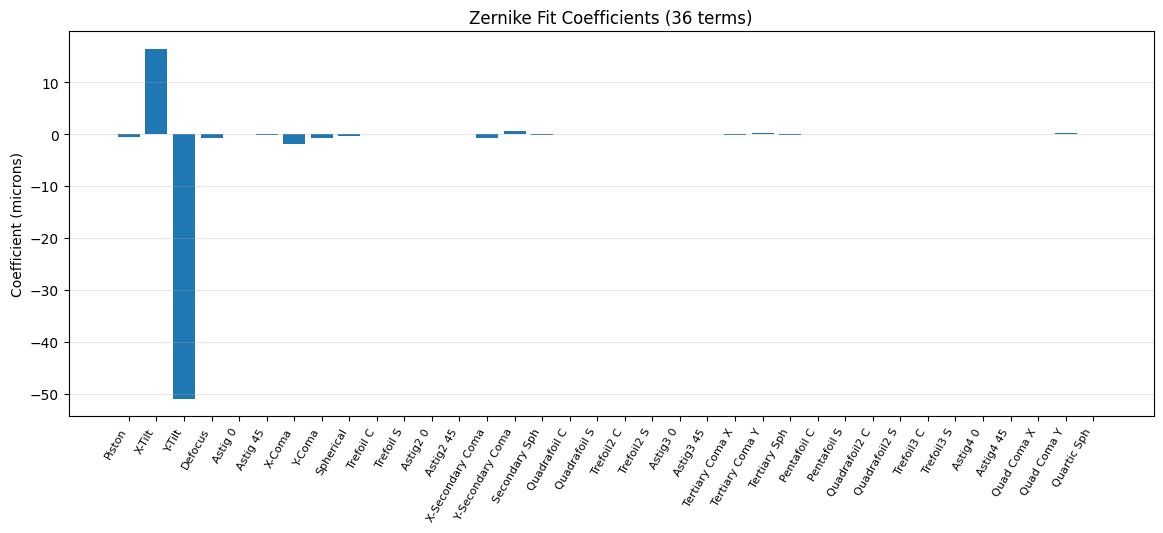

In [19]:
# Zernike term labels
zernike_names = [
    'Piston', 'X-Tilt', 'Y-Tilt', 'Defocus',
    'Astig 0', 'Astig 45', 'X-Coma', 'Y-Coma',
    'Spherical', 'Trefoil C', 'Trefoil S',
    'Astig2 0', 'Astig2 45', 'X-Secondary Coma', 'Y-Secondary Coma',
    'Secondary Sph', 'Quadrafoil C', 'Quadrafoil S',
    'Trefoil2 C', 'Trefoil2 S', 'Astig3 0', 'Astig3 45',
    'Tertiary Coma X', 'Tertiary Coma Y', 'Tertiary Sph',
    'Pentafoil C', 'Pentafoil S', 'Quadrafoil2 C', 'Quadrafoil2 S',
    'Trefoil3 C', 'Trefoil3 S', 'Astig4 0', 'Astig4 45',
    'Quad Coma X', 'Quad Coma Y', 'Quartic Sph'
]

# The following code plots the Zernike coefficients as a bar graph.
# The coefficients are multiplied by 1000 to convert from mm to microns.
# You need the coeffs evaluated from the least-squares fit above.
# If you named your coeffs variable differently, change it in the code below.

fig, ax = plt.subplots(figsize=(14, 5))
indices = range(len(coeffs))
bars = ax.bar(indices, coeffs * 1000)
ax.set_xticks(indices)
ax.set_xticklabels(zernike_names, rotation=60, ha='right', fontsize=8)
ax.set_ylabel('Coefficient (microns)')
ax.set_title('Zernike Fit Coefficients (36 terms)')
ax.grid(axis='y', alpha=0.3)
plt.show()

## Step 6: Remove piston, tip, and tilt

The first three Zernike terms are piston (a constant offset) and tip and tilt (a slope in x and in y). These can come from how the part was positioned on the instrument rather than from the surface itself, so we remove them.

In [20]:
# Make a copy of the coefficients and set the piston, x-tilt and y-tilt coefficients to zero.
# HINT: Python counts from 0, so those are the first three entries, indices 0, 1 and 2.
#       Use .copy() so that you don't change the original coeffs array!

coeffs_corrected = coeffs.copy()

coeffs_corrected[0] = 0   # Piston
coeffs_corrected[1] = 0   # X-Tilt
coeffs_corrected[2] = 0   # Y-Tilt

coeffs_corrected = coeffs.copy()
coeffs_corrected[0:3] = 0

## Step 7: Evaluate the fit on a new uniform XY grid

The original measurements was a spiral of discrete points. Because the fit is a smooth function of $(x, y)$, we can evaluate it anywhere, for example on a regular grid. This gives a standard 2D map that is easy to plot and to compare with other measurements.

In [25]:
# Build a new uniform grid (201 x 201 points) in normalized coordinates from -1 to +1.
# HINT: In NumPy meshgrid requires the linspace defined for each axis.
#       Keep these 2D arrays -- you will need their shape later to reshape the result for plotting.
x_grid = np.linspace(-1, 1, 201)
y_grid = np.linspace(-1, 1, 201)

xg, yg = np.meshgrid(x_grid, y_grid)

In [26]:
# Convert the grid into 1D arrays (the Zernike function needs column inputs)
# and find the points inside the unit circle.
# HINT: xg.ravel() flattens a 2D array into a 1D array.

xg1 = xg.ravel()
yg1 = yg.ravel()

inside = (xg1**2 + yg1**2) <= 1

xg_in = xg1[inside]
yg_in = yg1[inside]

In [28]:
# Evaluate the fitted error (with piston, tip and tilt removed) at the grid points inside the circle.
# HINT: Build the Zernike matrix for the inside points only
#       then multiply by the coefficients using the matrix multiplication operator @

ZGrid = Zernike(xg_in, yg_in)

error_grid_inside = ZGrid @ coeffs_corrected

In [30]:
# Put the results back into a 2D array so it can be plotted as an image.
# Points outside the circle have no data, so fill them with NaN ("not a number"); matplotlib leaves NaN blank.
# HINT: W1d = np.full(xg1.shape, np.nan)   makes an array shaped as xg1 filled with NaN
#       Use reshape(xg.shape) to reshape the data back to 2D based on the shape of xg and yg
#       This is why you kept the shape of xg and yg from before.

W1d = np.full(xg1.shape, np.nan)

W1d[inside] = error_grid_inside

W2d = W1d.reshape(X.shape)

print("xg:", xg.shape)
print("yg:", yg.shape)
print("W2d:", W2d.shape)

xg: (201, 201)
yg: (201, 201)
W2d: (201, 201)


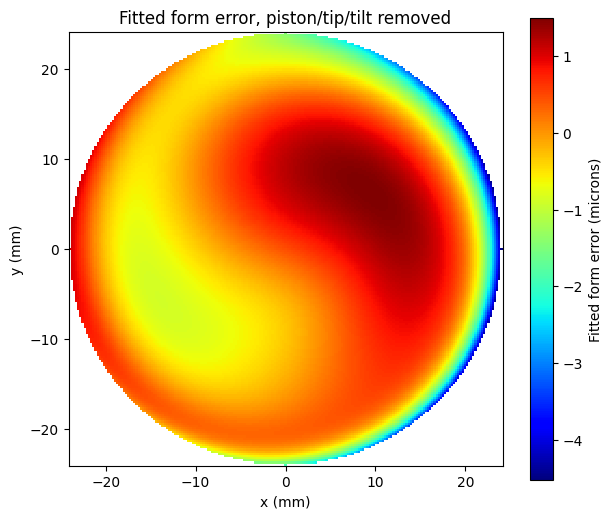

PV  = 6.016 microns
RMS = 0.920 microns


In [31]:
# Plot the fitted residual in microns, with the axes in mm (multiply the normalized grid by r_mask).

# I have added the full plotting code. You just need the variables xg, yg, W2d, and r_mask defined above.
# xg is the 2D array of x coordinates
# yg is the 2D array of y coordinates
# W2d is the 2D array of fitted form error values, and r_mask is the radius of the masked aperture in mm.
# If you named your variables differently, change them in the code below.

# HINT: plt.pcolormesh(xg*r_mask, yg*r_mask, W2d*1000, cmap='jet', shading='auto')
#       Then add plt.colorbar(label=...), plt.gca().set_aspect('equal'), axis labels, a title, and plt.show().
#       np.nanmax() and np.nanmin() ignore the NaN values if you want the peak-to-valley (PV) value,
#       and np.sqrt(np.nanmean(W2d**2)) gives the RMS.

plt.figure(figsize=(7, 6))
plt.pcolormesh(xg * r_mask, yg * r_mask, W2d * 1000, cmap='jet', shading='auto')
plt.colorbar(label='Fitted form error (microns)')
plt.gca().set_aspect('equal')
plt.xlabel('x (mm)')
plt.ylabel('y (mm)')
plt.title('Fitted form error, piston/tip/tilt removed')
plt.show()

pv = (np.nanmax(W2d) - np.nanmin(W2d)) * 1000
rms = np.sqrt(np.nanmean(W2d**2)) * 1000
print(f"PV  = {pv:.3f} microns")
print(f"RMS = {rms:.3f} microns")

What are the dominant residual Zernike terms?

The dominant residual Zernike terms seem to be some sort of coma, as seem from the two-lobed pattern on the scatter plot. A sign of coma can be seen from the bar graph in a preivous step as well.